### booktabs 的なテーブルの生成

1. matplotlib          -> 画像 (PNG) として出力。スライド向け。
2. pandas.to_latex      -> LaTeXコードを文字列生成。論文原稿向け、最も手軽。
3. tabx                 -> LaTeXコードをオブジェクト指向で構築。複雑な合成表向け。
4. pylatex (Tabular)    -> LaTeX文書全体をPythonから生成。文書ごと出力したい場合向け。

In [1]:
# 共通データ

DATA = {
    "Parameter": [r"$\phi_1$", r"$\phi_2$", r"$\theta_1$", r"$\sigma^2$"],
    "Estimate": ["0.612", "-0.208", "0.347", "0.0041"],
    "Std. Error": ["(0.083)", "(0.079)", "(0.091)", "(0.0006)"],
    "p-value": ["0.000", "0.008", "0.000", "-"],
}

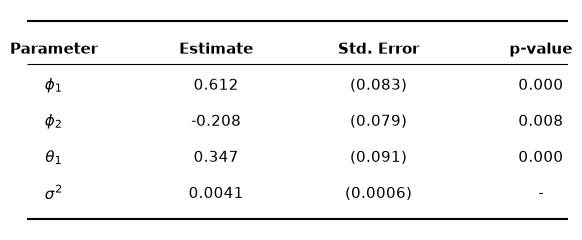

In [5]:
# 1. matplotlib

import matplotlib.pyplot as plt
import numpy as np

def make_matplotlib_table(data: dict) -> None:
    fig, ax = plt.subplots(figsize=(6, 2.5))
    ax.axis("off")
 
    n_rows = len(data["Parameter"])
    col_labels = list(data.keys())
    n_cols = len(col_labels)
 
    row_height = 1.0 / (n_rows + 2)
    y_positions = [1 - row_height * (i + 1.5) for i in range(n_rows + 1)]
    col_positions = np.linspace(0.05, 0.95, n_cols)
 
    # ヘッダー
    for j, label in enumerate(col_labels):
        ax.text(col_positions[j], y_positions[0], label,
                 ha="center", va="center", fontsize=11, fontweight="bold")
 
    # データ行
    for i in range(n_rows):
        for j, key in enumerate(col_labels):
            ax.text(col_positions[j], y_positions[i + 1], data[key][i],
                     ha="center", va="center", fontsize=11)
 
    # booktabs風の罫線 (\toprule, \midrule, \bottomrule に相当)
    top_y = 1 - row_height * 0.7
    mid_y = 1 - row_height * 1.9
    bottom_y = y_positions[-1] - row_height * 0.7
 
    ax.hlines(top_y, 0, 1, colors="black", linewidth=1.5)
    ax.hlines(mid_y, 0, 1, colors="black", linewidth=0.8)
    ax.hlines(bottom_y, 0, 1, colors="black", linewidth=1.5)
 
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom_y - 0.05, top_y + 0.05)
 
    plt.tight_layout()
    plt.show()
    

make_matplotlib_table(DATA)

In [8]:
# 2. pandas.to_latex

import pandas as pd

def make_pandas_latex(data: dict) -> str:
    df = pd.DataFrame(data)
    latex_str = df.to_latex(
        index=False,
        escape=False,
        column_format="lccc",
    )
    return latex_str

print(make_pandas_latex(DATA))

\begin{tabular}{lccc}
\toprule
Parameter & Estimate & Std. Error & p-value \\
\midrule
$\phi_1$ & 0.612 & (0.083) & 0.000 \\
$\phi_2$ & -0.208 & (0.079) & 0.008 \\
$\theta_1$ & 0.347 & (0.091) & 0.000 \\
$\sigma^2$ & 0.0041 & (0.0006) & - \\
\bottomrule
\end{tabular}



In [12]:
# 3. tabx

def make_tabx_latex(data: dict) -> str:
    from tabx import Table, Midrule
 
    column_names = list(data.keys())
    n_rows = len(data["Parameter"])
    rows = [
        [data[col][i] for col in column_names]
        for i in range(n_rows)
    ]
 
    # Table.from_values はヘッダー・ボディをまとめて渡すと
    # 自動で \toprule / \bottomrule を1回ずつ付与する。
    # \midrule はヘッダーとボディを分けて構築し、明示的に挿入する。
    header = Table.from_values([column_names])
    body = Table.from_values(rows)
    table = header / Midrule() / body
 
    return table.render()

print(make_tabx_latex(DATA))

\begin{tabular}{@{}cccc@{}}
  \toprule
  Parameter & Estimate & Std. Error & p-value \\
  \midrule
  $\phi_1$ & 0.612 & (0.083) & 0.000 \\
  $\phi_2$ & -0.208 & (0.079) & 0.008 \\
  $\theta_1$ & 0.347 & (0.091) & 0.000 \\
  $\sigma^2$ & 0.0041 & (0.0006) & - \\
  \bottomrule
\end{tabular}


In [13]:
# 4. pylatex

def make_pylatex_table(data: dict) -> str:
    from pylatex import Tabular
    from pylatex.utils import NoEscape
 
    n_cols = len(data)
    table = Tabular("l" + "c" * (n_cols - 1), booktabs=True)
 
    table.add_row([NoEscape(col) for col in data.keys()])
    table.add_hline()
 
    n_rows = len(data["Parameter"])
    for i in range(n_rows):
        row = [NoEscape(data[col][i]) for col in data.keys()]
        table.add_row(row)
 
    return table.dumps()

print(make_pylatex_table(DATA))

\begin{tabular}{@{}lccc@{}}%
\toprule%
Parameter&Estimate&Std. Error&p-value\\%
\midrule%
$\phi_1$&0.612&(0.083)&0.000\\%
$\phi_2$&-0.208&(0.079)&0.008\\%
$\theta_1$&0.347&(0.091)&0.000\\%
$\sigma^2$&0.0041&(0.0006)&-\\\bottomrule%
%
\end{tabular}
